In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             average_precision_score, confusion_matrix,
                             roc_curve, ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [2]:
df = pd.read_csv("/content/hiv1_protease_padel_full.csv")

fp_cols = [c for c in df.columns if c.startswith("PubchemFP") or
           (c.startswith("FP") and c[2:].isdigit())]

X = df[fp_cols].values.astype(np.float32)
y = df["binary_label"].values.astype(np.float32)      # 1 = active, 0 = inactive

print("Samples:", X.shape[0], "| features:", X.shape[1])
print("Active fraction:", y.mean().round(3))

Samples: 2577 | features: 881
Active fraction: 0.917


In [3]:
X_tmp, X_te, y_tmp, y_te = train_test_split(X, y, test_size=0.15, stratify=y, random_state=SEED)
X_tr, X_va, y_tr, y_va   = train_test_split(X_tmp, y_tmp, test_size=0.1765,
                                            stratify=y_tmp, random_state=SEED)

# Remove near-constant fingerprint bits (fit on train only)
vt = VarianceThreshold(0.01).fit(X_tr)
X_tr, X_va, X_te = vt.transform(X_tr), vt.transform(X_va), vt.transform(X_te)
kept_cols = np.array(fp_cols)[vt.get_support()]
print("Features after variance filter:", X_tr.shape[1])
print("Train/Val/Test:", len(y_tr), len(y_va), len(y_te))

def make_loader(Xa, ya, shuffle, bs=64):
    ds = TensorDataset(torch.tensor(Xa, dtype=torch.float32),
                       torch.tensor(ya, dtype=torch.float32))
    return DataLoader(ds, batch_size=bs, shuffle=shuffle, drop_last=shuffle)

train_loader = make_loader(X_tr, y_tr, True)
val_loader   = make_loader(X_va, y_va, False)
test_loader  = make_loader(X_te, y_te, False)

Features after variance filter: 388
Train/Val/Test: 1803 387 387


In [4]:
class DNN(nn.Module):
    def __init__(self, in_dim):
        super().__init__()

        # ---- Block 1: in_dim -> 512 ----
        self.fc1   = nn.Linear(in_dim, 512)
        self.bn1   = nn.BatchNorm1d(512)
        self.act1  = nn.ReLU()
        self.drop1 = nn.Dropout(0.3)

        # ---- Block 2: 512 -> 256 ----
        self.fc2   = nn.Linear(512, 256)
        self.bn2   = nn.BatchNorm1d(256)
        self.act2  = nn.ReLU()
        self.drop2 = nn.Dropout(0.3)

        # ---- Block 3: 256 -> 64 ----
        self.fc3   = nn.Linear(256, 64)
        self.bn3   = nn.BatchNorm1d(64)
        self.act3  = nn.ReLU()
        self.drop3 = nn.Dropout(0.3)

        # ---- Output: 64 -> 1 logit (binary) ----
        self.out = nn.Linear(64, 1)

    def forward(self, x):
        # Block 1
        x = self.fc1(x)
        x = self.bn1(x)
        x = self.act1(x)
        x = self.drop1(x)

        # Block 2
        x = self.fc2(x)
        x = self.bn2(x)
        x = self.act2(x)
        x = self.drop2(x)

        # Block 3
        x = self.fc3(x)
        x = self.bn3(x)
        x = self.act3(x)
        x = self.drop3(x)

        # Output (raw logit; sigmoid is applied inside BCEWithLogitsLoss / predict_proba)
        x = self.out(x)
        return x.squeeze(1)

model = DNN(X_tr.shape[1]).to(device)
print(model)
print("Parameters:", sum(p.numel() for p in model.parameters()))

DNN(
  (fc1): Linear(in_features=388, out_features=512, bias=True)
  (bn1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (act1): ReLU()
  (drop1): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (bn2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (act2): ReLU()
  (drop2): Dropout(p=0.3, inplace=False)
  (fc3): Linear(in_features=256, out_features=64, bias=True)
  (bn3): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (act3): ReLU()
  (drop3): Dropout(p=0.3, inplace=False)
  (out): Linear(in_features=64, out_features=1, bias=True)
)
Parameters: 348673


In [5]:
# Class imbalance: weight the positive class by (#neg / #pos)
pos_weight = torch.tensor((y_tr == 0).sum() / (y_tr == 1).sum(), dtype=torch.float32).to(device)
print("pos_weight:", pos_weight.item())

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=5)

@torch.no_grad()
def predict_proba(model, loader):
    model.eval()
    out = [torch.sigmoid(model(xb.to(device))).cpu() for xb, _ in loader]
    return torch.cat(out).numpy()

@torch.no_grad()
def eval_loss(model, loader):
    model.eval(); total, n = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        total += criterion(model(xb), yb).item() * len(yb); n += len(yb)
    return total / n

pos_weight: 0.09008464217185974


In [6]:
train_eval_loader = make_loader(X_tr, y_tr, False)     # unshuffled copy of train set for evaluation

EPOCHS, PATIENCE = 200, 20
BEST_WEIGHTS_PATH = "hiv1_dnn_best_weights.pt"         # weights only, updated during training
CHECKPOINT_PATH   = "hiv1_dnn_best_checkpoint.pt"      # full checkpoint, saved at the end

best_auc, best_state, best_epoch, wait = -1.0, None, 0, 0
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_auc": []}

for epoch in range(1, EPOCHS + 1):
    # ---- train ----
    model.train(); running, n = 0.0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        running += loss.item() * len(yb); n += len(yb)

    # ---- evaluate (eval mode: no dropout, batch norm uses running stats) ----
    train_prob = predict_proba(model, train_eval_loader)
    val_prob   = predict_proba(model, val_loader)
    train_acc  = accuracy_score(y_tr, train_prob >= 0.5)
    val_acc    = accuracy_score(y_va, val_prob >= 0.5)
    val_auc    = roc_auc_score(y_va, val_prob)

    history["train_loss"].append(running / n)
    history["val_loss"].append(eval_loss(model, val_loader))
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["val_auc"].append(val_auc)
    scheduler.step(val_auc)

    # ---- early stopping / keep and save best model (by validation AUC) ----
    if val_auc > best_auc:
        best_auc, best_epoch, wait = val_auc, epoch, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, BEST_WEIGHTS_PATH)       # overwritten on every improvement
    else:
        wait += 1

    if epoch % 5 == 0 or epoch == 1:
        print(f"epoch {epoch:3d} | loss {history['train_loss'][-1]:.4f}/{history['val_loss'][-1]:.4f} "
              f"| acc {train_acc:.4f}/{val_acc:.4f} | val AUC {val_auc:.4f}")
    if wait >= PATIENCE:
        print(f"Early stopping at epoch {epoch} (best val AUC {best_auc:.4f} at epoch {best_epoch})")
        break

# ---- load best weights back into the model ----
model.load_state_dict(best_state)

# ---- save full checkpoint (weights + info needed to rebuild and reuse the model) ----
torch.save({
    "state_dict": best_state,
    "in_dim": X_tr.shape[1],
    "kept_cols": list(kept_cols),          # fingerprint columns kept by the variance filter
    "best_val_auc": float(best_auc),
    "best_epoch": int(best_epoch),
}, CHECKPOINT_PATH)

print(f"\nBest model: epoch {best_epoch}, val AUC {best_auc:.4f}")
print(f"Saved: {BEST_WEIGHTS_PATH} and {CHECKPOINT_PATH}")

epoch   1 | loss 0.0928/0.0783 | acc 0.8514/0.8088 | val AUC 0.8659
epoch   5 | loss 0.0444/0.0654 | acc 0.9301/0.8708 | val AUC 0.9001
epoch  10 | loss 0.0330/0.0631 | acc 0.9346/0.8786 | val AUC 0.9054
epoch  15 | loss 0.0240/0.0712 | acc 0.9357/0.8734 | val AUC 0.9000
epoch  20 | loss 0.0242/0.0765 | acc 0.9362/0.8682 | val AUC 0.8953
epoch  25 | loss 0.0190/0.0757 | acc 0.9584/0.9070 | val AUC 0.9030
Early stopping at epoch 28 (best val AUC 0.9085 at epoch 8)

Best model: epoch 8, val AUC 0.9085
Saved: hiv1_dnn_best_weights.pt and hiv1_dnn_best_checkpoint.pt


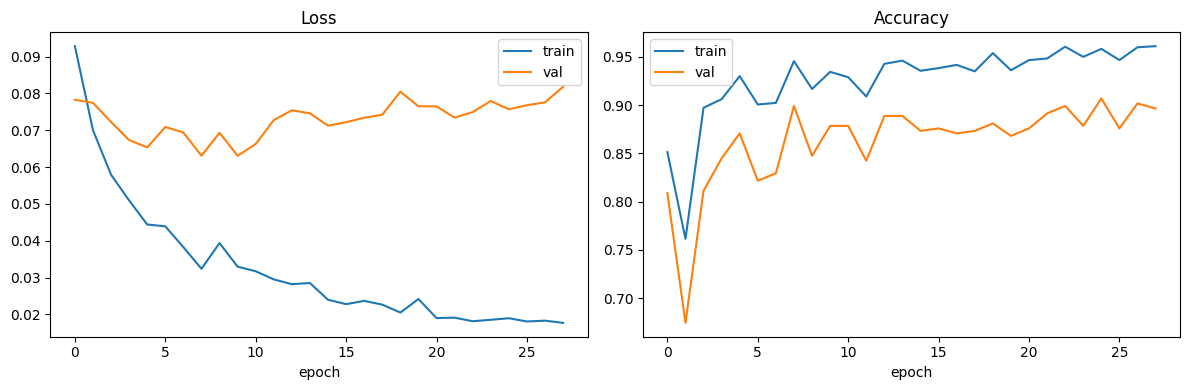

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history["train_loss"], label="train")
ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()

ax[1].plot(history["train_acc"], label="train")
ax[1].plot(history["val_acc"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()

plt.tight_layout(); plt.show()

In [8]:
val_prob  = predict_proba(model, val_loader)
test_prob = predict_proba(model, test_loader)

# Best threshold by balanced accuracy on validation data
thresholds = np.linspace(0.05, 0.95, 91)
best_t = thresholds[np.argmax([balanced_accuracy_score(y_va, val_prob >= t) for t in thresholds])]
print("Chosen threshold:", round(float(best_t), 2))

def report(thr):
    pred = (test_prob >= thr).astype(int)
    return {"threshold": round(float(thr), 2),
            "accuracy": accuracy_score(y_te, pred),
            "balanced_acc": balanced_accuracy_score(y_te, pred),
            "precision": precision_score(y_te, pred, zero_division=0),
            "recall": recall_score(y_te, pred),
            "F1": f1_score(y_te, pred),
            "ROC_AUC": roc_auc_score(y_te, test_prob),
            "PR_AUC": average_precision_score(y_te, test_prob)}

res = pd.DataFrame({"DNN (thr=0.5)": report(0.5),
                    "DNN (tuned thr)": report(best_t)}).T.round(3)
display(res)
res.to_csv("dnn_test_results.csv")

Chosen threshold: 0.49


,threshold,accuracy,balanced_acc,precision,recall,F1,ROC_AUC,PR_AUC
DNN (thr=0.5),0.50,0.925,0.817,0.971,0.946,0.959,0.861,0.981
DNN (tuned thr),0.49,0.925,0.817,0.971,0.946,0.959,0.861,0.981


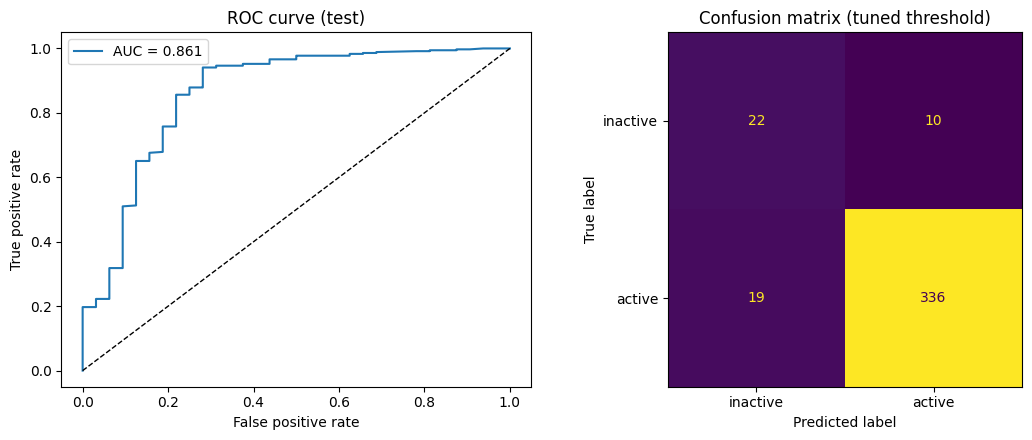

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

fpr, tpr, _ = roc_curve(y_te, test_prob)
ax[0].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_te, test_prob):.3f}")
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curve (test)"); ax[0].legend()

cm = confusion_matrix(y_te, (test_prob >= best_t).astype(int))
ConfusionMatrixDisplay(cm, display_labels=["inactive", "active"]).plot(ax=ax[1], colorbar=False)
ax[1].set_title("Confusion matrix (tuned threshold)")

plt.tight_layout(); plt.show()

In [10]:
torch.save({
    "state_dict": best_state,
    "in_dim": X_tr.shape[1],
    "kept_cols": list(kept_cols),
    "best_val_auc": float(best_auc),
    "best_epoch": int(best_epoch),
    "threshold": float(best_t),
}, "hiv1_dnn_best_checkpoint.pt")

# from google.colab import files
# files.download("hiv1_dnn_best_checkpoint.pt")
# files.download("dnn_test_results.csv")

In [11]:
ckpt = torch.load("/content/hiv1_dnn_best_checkpoint.pt", map_location=device,weights_only=False)
model = DNN(ckpt["in_dim"]).to(device)
model.load_state_dict(ckpt["state_dict"])
model.eval()
threshold = ckpt["threshold"]

# New molecules need the same fingerprint columns, filtered to ckpt["kept_cols"]:
# X_new = new_df[ckpt["kept_cols"]].values.astype(np.float32)
# prob = torch.sigmoid(model(torch.tensor(X_new).to(device))).detach().cpu().numpy()
# pred = (prob >= threshold).astype(int)

In [12]:
test_prob_reloaded = predict_proba(model, test_loader)
pred = (test_prob_reloaded >= threshold).astype(int)

print(f"Test accuracy:          {accuracy_score(y_te, pred):.4f}")
print(f"Test balanced accuracy: {balanced_accuracy_score(y_te, pred):.4f}")
print(f"Test ROC-AUC:           {roc_auc_score(y_te, test_prob_reloaded):.4f}")


Test accuracy:          0.9251
Test balanced accuracy: 0.8170
Test ROC-AUC:           0.8614
